# Statistical Plots and Distribution Analysis (Project 2)

In [20]:
#Loading the dataset
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("titanic_cleaned.csv")
print(df.shape)
print(df.head())
print(df.dtypes)

(891, 14)
   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult male  embark town alive  alone  
0    man        True  Southampton    no  False  
1  woman       False    Cherbourg   yes  False  
2  woman       False  Southampton   yes   True  
3  woman       False  Southampton   yes  False  
4    man        True  Southampton    no   True  
survived         int64
pclass           int64
sex             object
age            float64
sibsp            int64
parch            int64
fare           float64
embarked        object
class           object
who             object
adult mal

### Histograms, KDEs and Boxplots

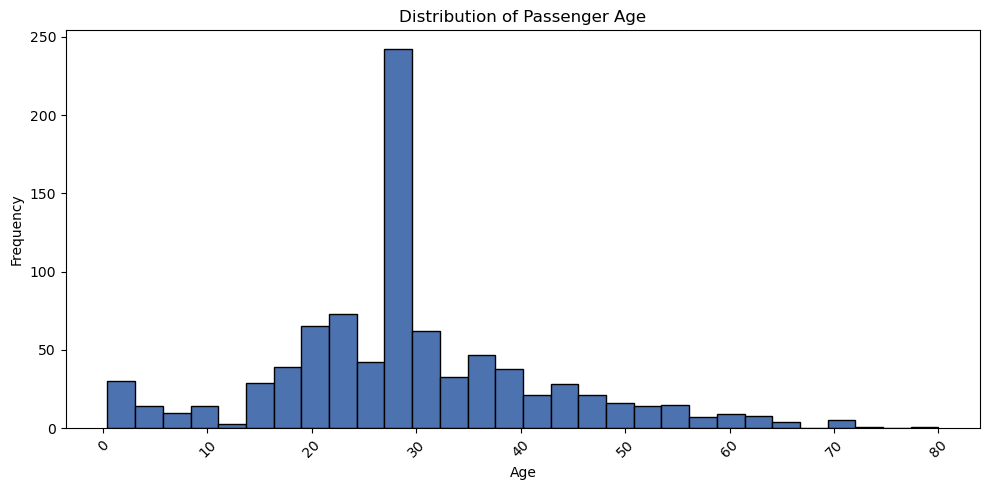

In [48]:
#Histogram : Age Distribution
plt.figure(figsize=(10,5))
plt.hist(df["age"], bins=30, color="#4C72B0", edgecolor="black")
plt.title("Distribution of Passenger Age")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

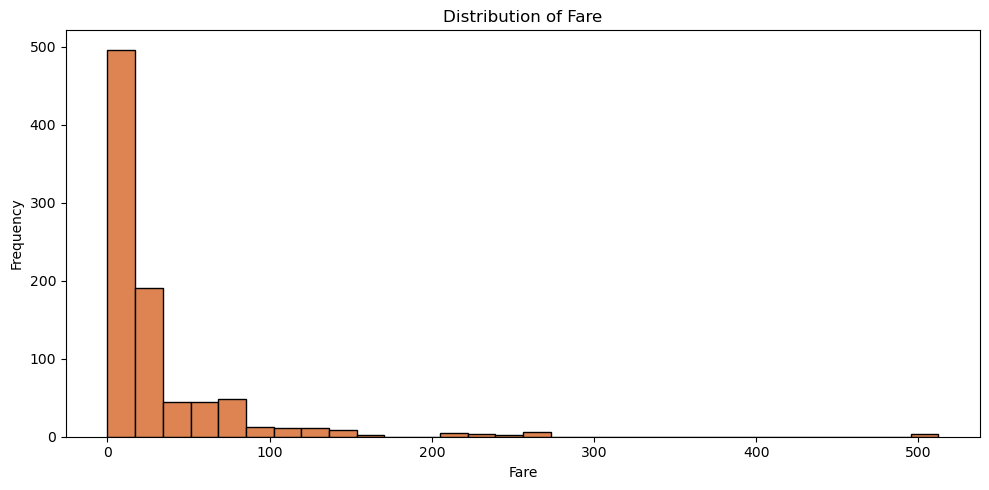

In [47]:
#Histogram : Fare Distribution
plt.figure(figsize=(10,5))
plt.hist(df["fare"], bins=30, color="#DD8452", edgecolor="black")
plt.title("Distribution of Fare")
plt.xlabel("Fare")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

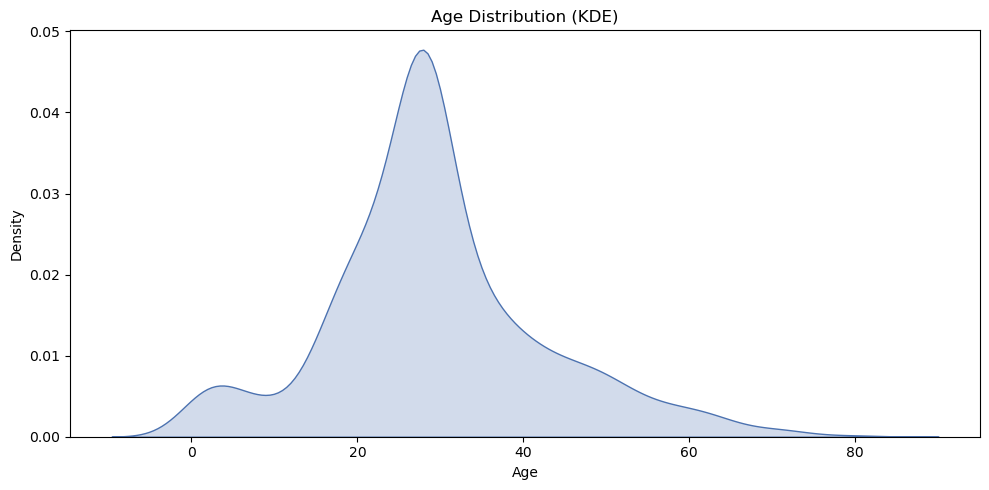

In [25]:
#KDE : Age
plt.figure(figsize=(10,5))
sns.kdeplot(df["age"], fill=True, color="#4C72B0")
plt.title("Age Distribution (KDE)")
plt.xlabel("Age")
plt.tight_layout()
plt.show()

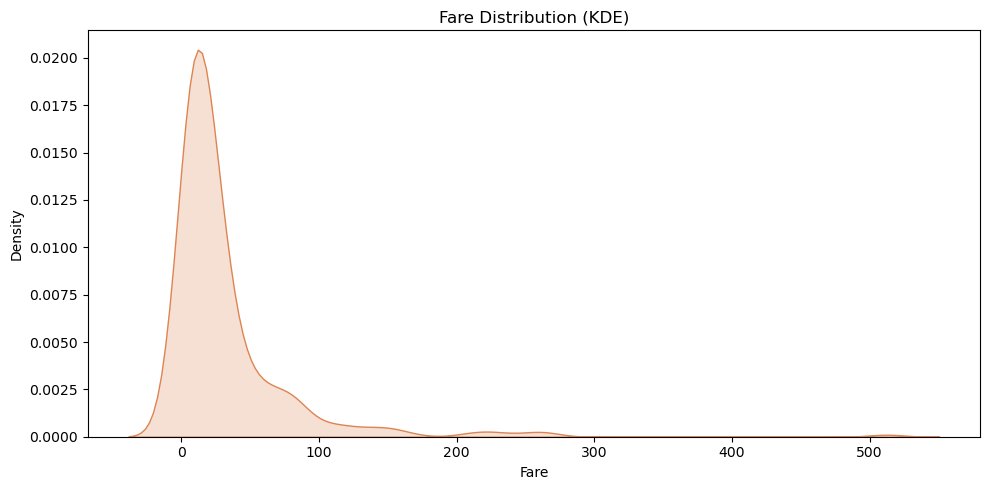

In [26]:
#KDE : Fare
plt.figure(figsize=(10,5))
sns.kdeplot(df["fare"], fill=True, color="#DD8452")
plt.title("Fare Distribution (KDE)")
plt.xlabel("Fare")
plt.tight_layout()
plt.show()

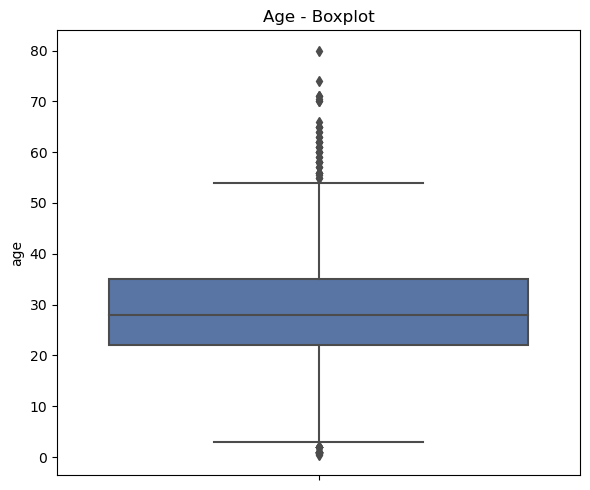

In [28]:
#Boxplot : Age
plt.figure(figsize=(6,5))
sns.boxplot(y=df["age"], color="#4C72B0")
plt.title("Age - Boxplot")
plt.tight_layout()
plt.show()

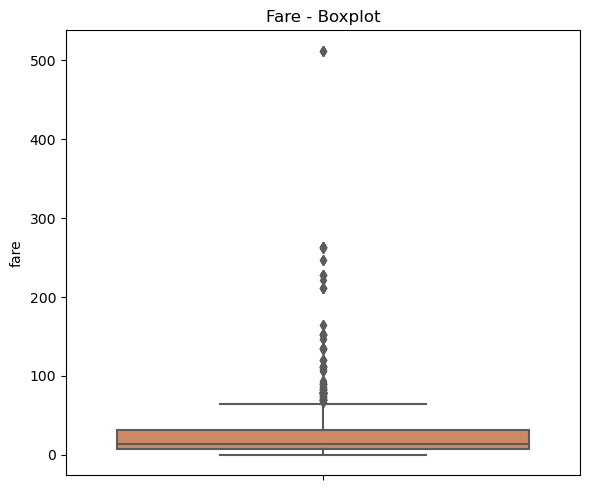

In [29]:
#Boxplot - Fare
plt.figure(figsize=(6,5))
sns.boxplot(y=df["fare"], color="#DD8452")
plt.title("Fare - Boxplot")
plt.tight_layout()
plt.show()

### Comparing Distributions Across Groups

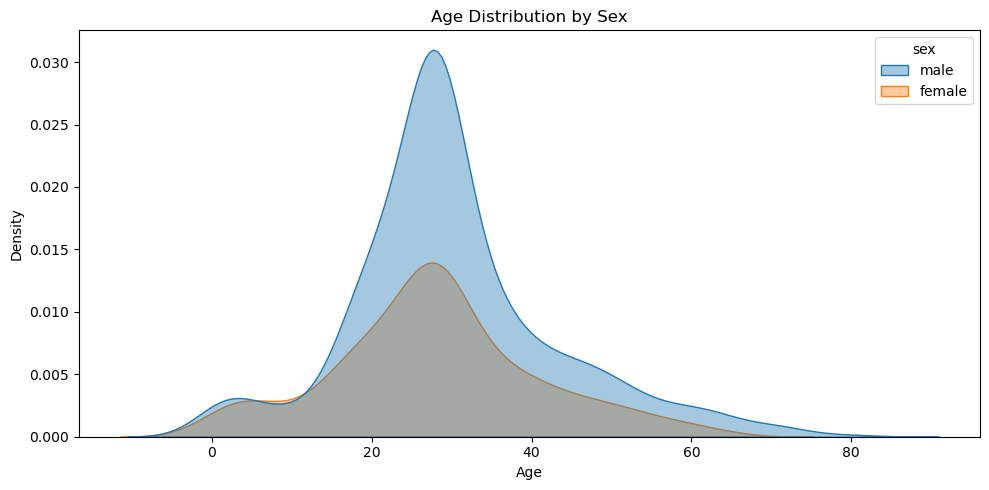

In [30]:
#Age distribution by sex (overlapping KDE)
plt.figure(figsize=(10,5))
sns.kdeplot(data=df, x="age", hue="sex", fill=True, alpha=0.4)
plt.title("Age Distribution by Sex")
plt.xlabel("Age")
plt.tight_layout()
plt.show()

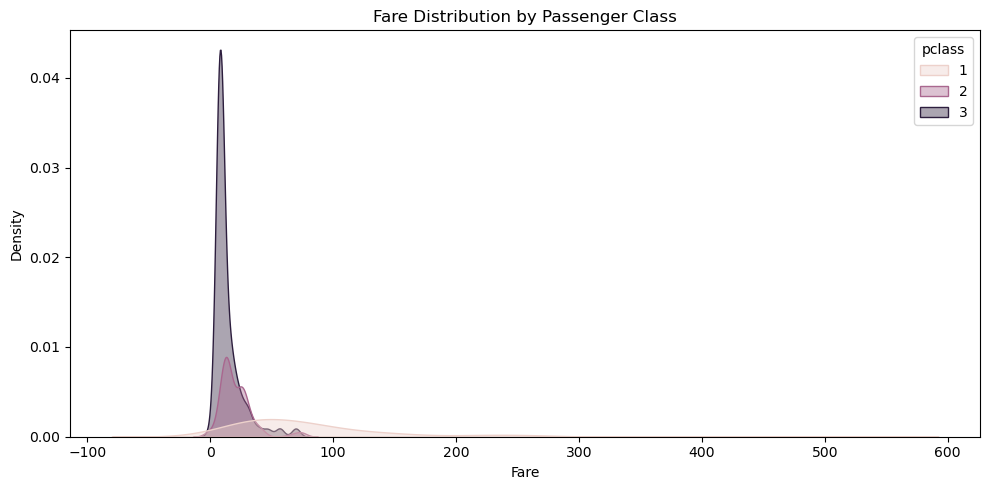

In [31]:
#Fare distribution by passenger class 
plt.figure(figsize=(10,5))
sns.kdeplot(data=df, x="fare", hue="pclass", fill=True, alpha=0.4)
plt.title("Fare Distribution by Passenger Class")
plt.xlabel("Fare")
plt.tight_layout()
plt.show()

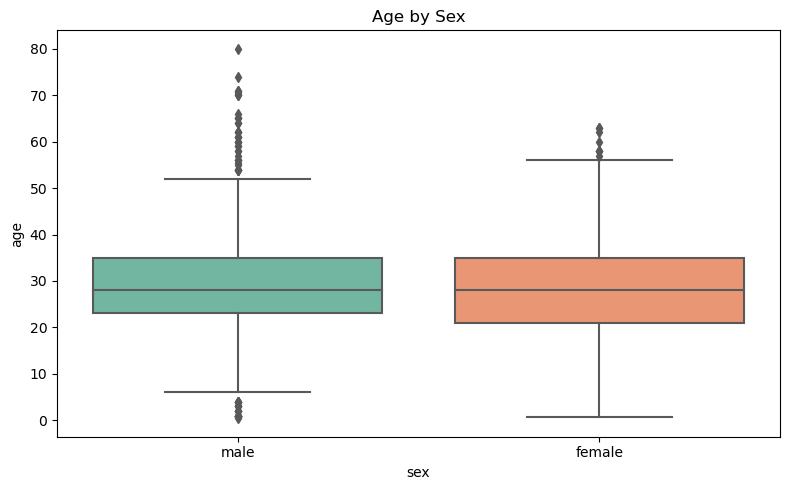

In [32]:
#Boxplot : Age by sex(side-by-side comparison)
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="sex", y="age", palette="Set2")
plt.title("Age by Sex")
plt.tight_layout()
plt.show()

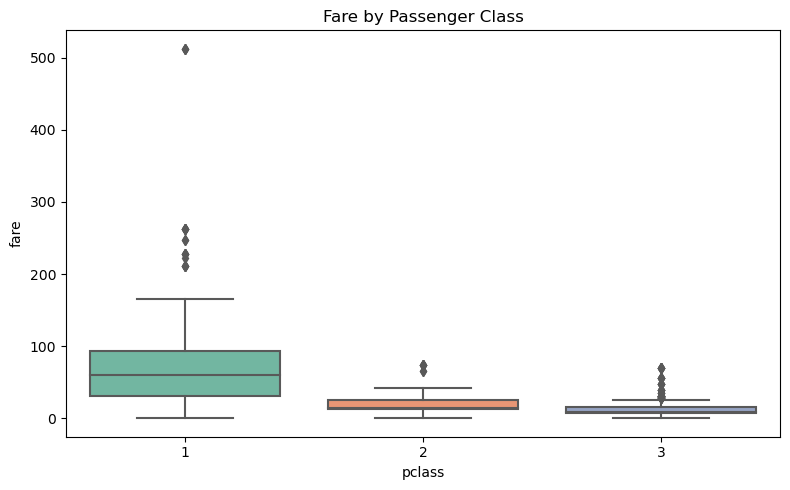

In [33]:
#Boxplot : Fare by passenger class 
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="pclass", y="fare", palette="Set2")
plt.title("Fare by Passenger Class")
plt.tight_layout()
plt.show()

In [36]:
#Numeric Comparison
print(df.groupby("sex")["age"].agg(["mean", "median", "std"]))
print(df.groupby("pclass")["fare"].agg(["mean", "median", "std"]))

             mean  median        std
sex                                 
female  27.929936    28.0  12.860189
male    30.140676    28.0  13.050847
             mean   median        std
pclass                               
1       84.154687  60.2875  78.380373
2       20.662183  14.2500  13.417399
3       13.675550   8.0500  11.778142


### Detecting Outliers and Commenting on Skewness/Spread

In [41]:
from scipy import stats
#Quantifying Skewness
age_skew = df["age"].skew()
fare_skew = df["fare"].skew()
print(f"Age Skewness : {age_skew:.2f}")
print(f"Fare Skewness : {fare_skew:.2f}")

Age Skewness : 0.51
Fare Skewness : 4.79


In [44]:
#Outlier Detection using the IQR method
def detect_outliers_iqr(column) :
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    return outliers, upper_bound, lower_bound
age_outliers, age_low, age_high = detect_outliers_iqr("age")
fare_outliers, fare_low, fare_high = detect_outliers_iqr("fare")
print(f"\nAge Outliers : {len(age_outliers)} rows (outside {age_low:.1f} to {age_high:.1f})")
print(f"\nFare Outliers : {len(fare_outliers)} rows (outside {fare_low:.1f} to {fare_high:.1f})")


Age Outliers : 66 rows (outside 54.5 to 2.5)

Fare Outliers : 116 rows (outside 65.6 to -26.7)


In [45]:
#Spread (standard deviation, range)
print(f"\nAge - std : {df['age'].std():.2f}, range : {df['age'].min()} to {df['age'].max()}")
print(f"\nFare - std : {df['fare'].std():.2f}, range : {df['age'].min():.2f} to {df['age'].max():.2f}")


Age - std : 13.02, range : 0.42 to 80.0

Fare - std : 49.69, range : 0.42 to 80.00


### Outlier, Skewness and Spread Analysis
**Fare** shows strong positive (right) skew, with a skewness value of 4.79. This means most ticket prices are clustered at the lower end, with a long tail of a small number of very expensive tickets pulling the distribution to the right. Using the IQR method, 116 rows were flagged as outliers - fares above 65.6. These outliers likely correspond to 1st class passengers who paid significantly more than the typical fare, which is consistent with the earlier boxplot comparison by passenger class. The standard deviation of fare (49.69) is large relative to its median, confirming that fare is a highly spread-out, volatile variable.

**Age**, by contrast, is much closer to a symmetric distribution, with a skewness value of 0.51 - close to 0 indicates minimal asymmtery. Only 66 rows were flagged as outliers, meaning extreme ages (either very young infants or elderly passengers) are rare but present. It's worth noting that age's distribution is slightly influenced by the imputation strategy used during cleaning : missing ages were filled with the median, which creates a small artificial spike at that value and slightly reduces the dataset's natural variability compared to the true (unknown) original distribution.

Overall, fare is the more skewed and outlier-prone variable of the two, which makes sense given ticket prices can vary enormously by class and cabin type, while age is more naturally bounded, evenly distributed human characteristic.

### Exporting Plots and One-Paragraph Interpretation

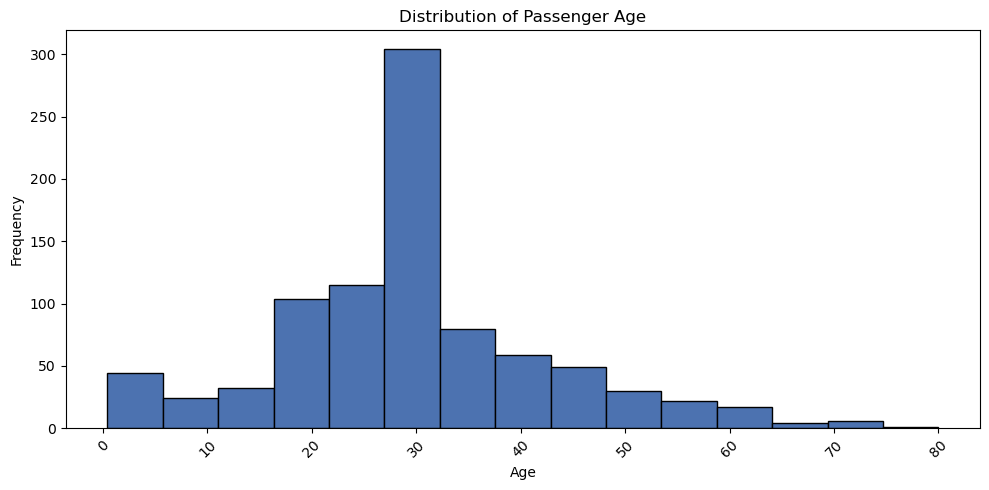

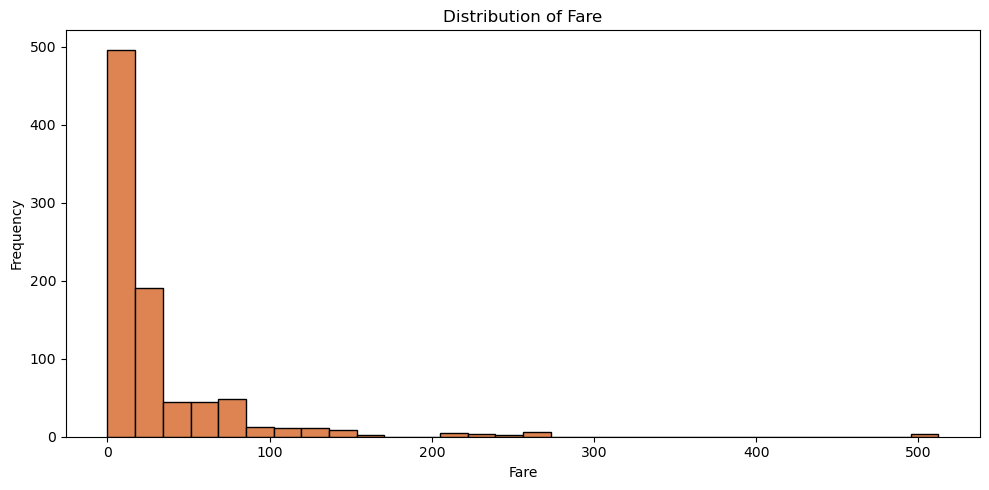

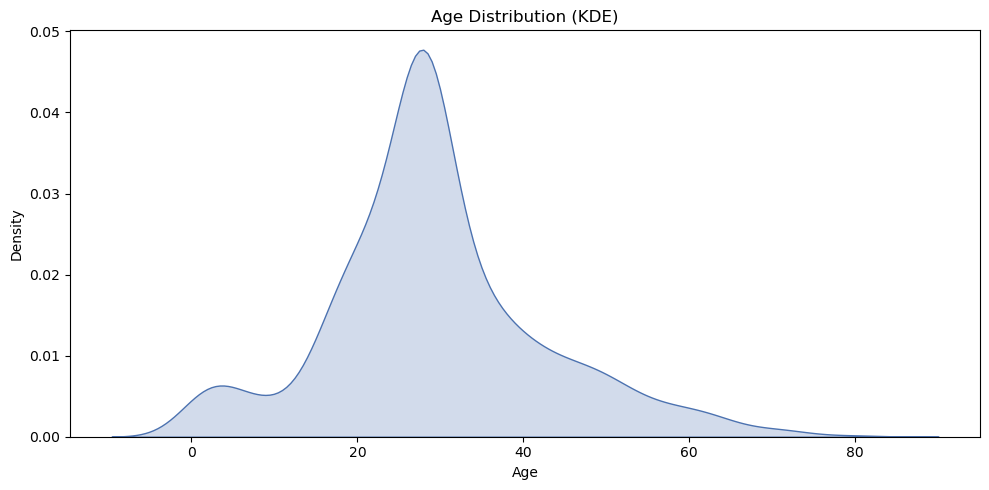

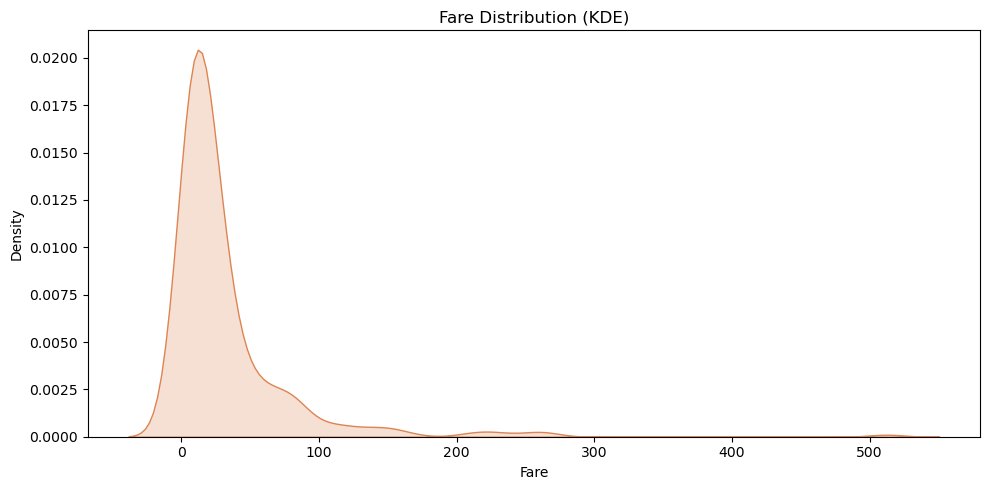

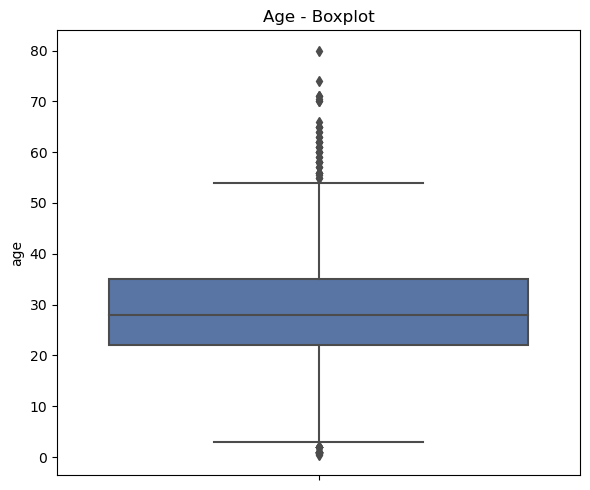

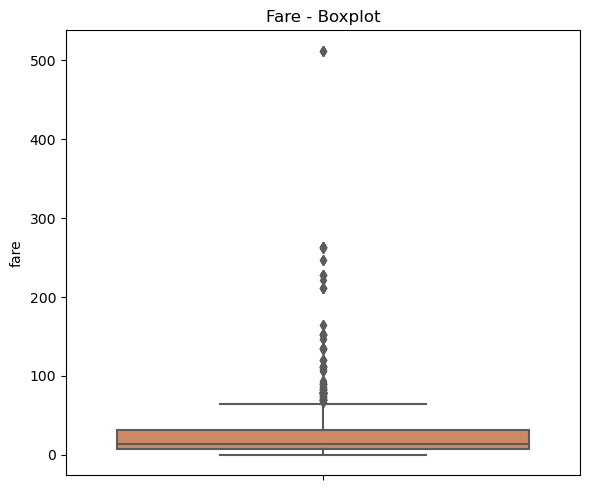

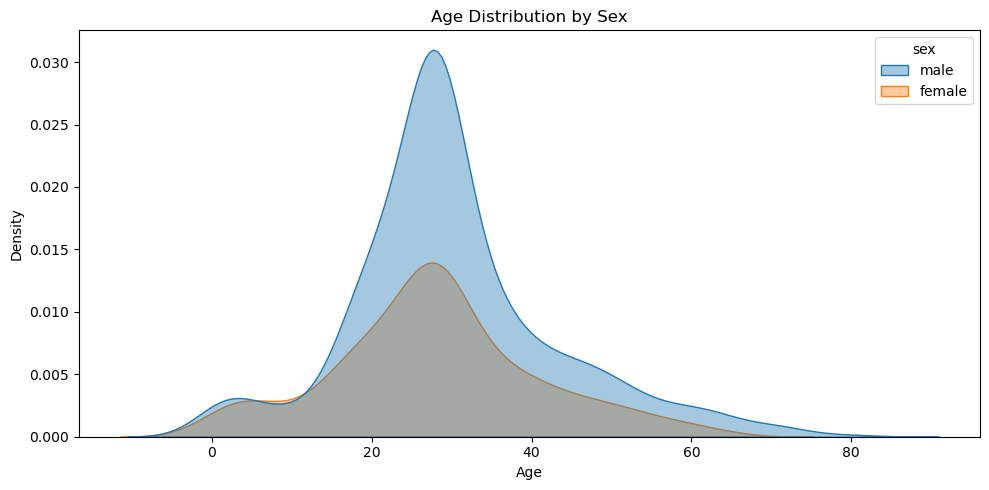

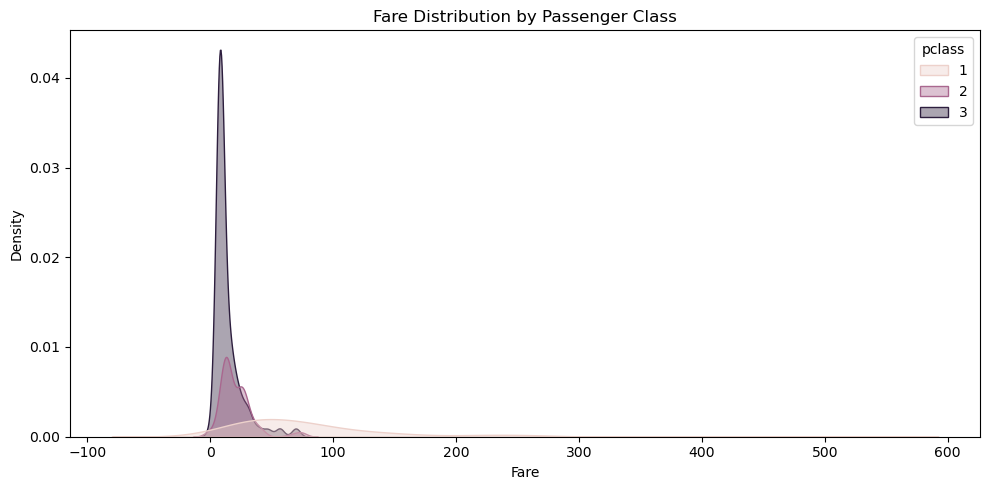

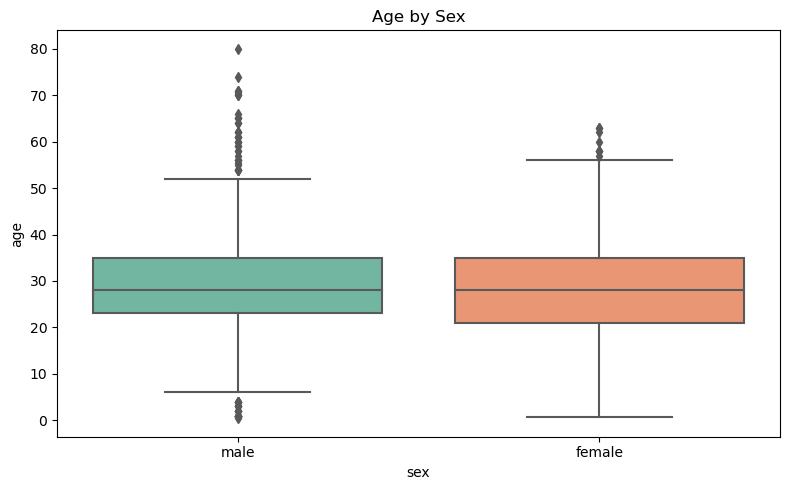

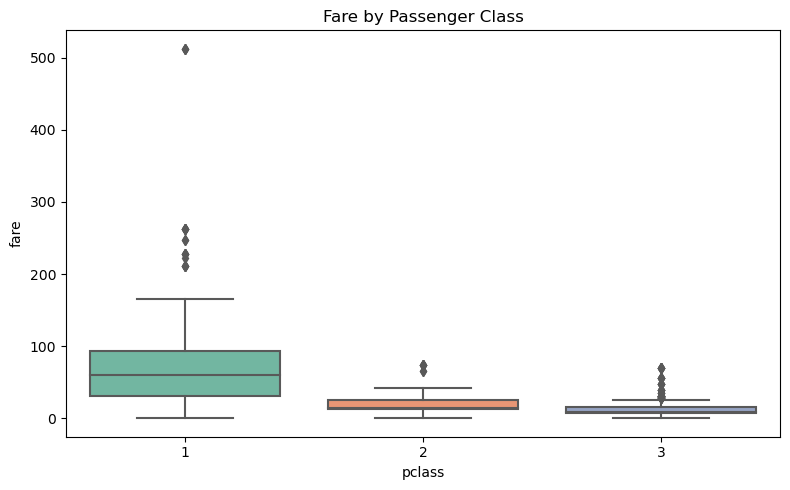

In [49]:
#Age Histogram
plt.figure(figsize=(10,5))
plt.hist(df["age"], bins=15, color="#4C72B0", edgecolor="black")
plt.title("Distribution of Passenger Age")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("age_histogram.png", dpi=150)
plt.show()

#Fare Histogram
plt.figure(figsize=(10,5))
plt.hist(df["fare"], bins=30, color="#DD8452", edgecolor="black")
plt.title("Distribution of Fare")
plt.xlabel("Fare")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig("fare_histogram.png", dpi=150)
plt.show()

#Age KDE
plt.figure(figsize=(10,5))
sns.kdeplot(df["age"], fill=True, color="#4C72B0")
plt.title("Age Distribution (KDE)")
plt.xlabel("Age")
plt.tight_layout()
plt.savefig("age_kde.png", dpi=150)
plt.show()

#Fare KDE
plt.figure(figsize=(10,5))
sns.kdeplot(df["fare"], fill=True, color="#DD8452")
plt.title("Fare Distribution (KDE)")
plt.xlabel("Fare")
plt.tight_layout()
plt.savefig("fare_kde.png", dpi=150)
plt.show()

#Age Boxplot
plt.figure(figsize=(6,5))
sns.boxplot(y=df["age"], color="#4C72B0")
plt.title("Age - Boxplot")
plt.tight_layout()
plt.savefig("age_boxplot.png", dpi=150)
plt.show()

#Fare Boxplot
plt.figure(figsize=(6,5))
sns.boxplot(y=df["fare"], color="#DD8452")
plt.title("Fare - Boxplot")
plt.tight_layout()
plt.savefig("fare_boxplot.png", dpi=150)
plt.show()

#Age by sex KDE
plt.figure(figsize=(10,5))
sns.kdeplot(data=df, x="age", hue="sex", fill=True, alpha=0.4)
plt.title("Age Distribution by Sex")
plt.xlabel("Age")
plt.tight_layout()
plt.savefig("age_by_sex_kde.png", dpi=150)
plt.show()

#Fare by class KDE
plt.figure(figsize=(10,5))
sns.kdeplot(data=df, x="fare", hue="pclass", fill=True, alpha=0.4)
plt.title("Fare Distribution by Passenger Class")
plt.xlabel("Fare")
plt.tight_layout()
plt.savefig("fare_by_class_kde.png", dpi=150)
plt.show()

#Age by sex Boxplot
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="sex", y="age", palette="Set2")
plt.title("Age by Sex")
plt.tight_layout()
plt.savefig("age_by_sex_boxplot.png", dpi=150)
plt.show()

#Fare by class Boxplot
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="pclass", y="fare", palette="Set2")
plt.title("Fare by Passenger Class")
plt.tight_layout()
plt.savefig("fare_by_class_boxplot.png", dpi=150)
plt.show()

In [50]:
#Interpretation
interpretation = f"""
TITANIC DISTRIBUTION ANALYSIS - INTERPRETATION 
=================================================
Age skewness : {df['age'].skew():.2f}
Fare skewness : {df['fare'].skew():.2f}

Fare is strongly right-skewed, reflecting a small number of very expensive tickets (mostly 1st class) pulling the distribution's tail to the right. Age is much closer to symmetric, with the imputed median values slightly reducing its natural variability. Outlier analysis using the IQR method confirms fare has substantially more extreme values than age, and the group comparisons show passenger class drives large differences in fare (1st class paying far more on average), while sex shows only a modest difference in age distribution.
"""
print(interpretation)
with open("distribution_interpretation.txt", "w") as f :
    f.write(interpretation)
print("Saved distribution_interpretation.txt")


TITANIC DISTRIBUTION ANALYSIS - INTERPRETATION 
Age skewness : 0.51
Fare skewness : 4.79

Fare is strongly right-skewed, reflecting a small number of very expensive tickets (mostly 1st class) pulling the distribution's tail to the right. Age is much closer to symmetric, with the imputed median values slightly reducing its natural variability. Outlier analysis using the IQR method confirms fare has substantially more extreme values than age, and the group comparisons show passenger class drives large differences in fare (1st class paying far more on average), while sex shows only a modest difference in age distribution.

Saved distribution_interpretation.txt
